# 03 · `combine_hemis.py`: merging the two hemispheres

NextBrain segments each hemisphere separately and writes two volumes with
**different grids** (shape and affine). `combine_hemis(left, right, save,
save_sides)` places both on a single grid. It returns:

* `combined`: the union of the two label maps (left wins where they overlap)
* `sides`: a lateralisation mask, 1 = left, 2 = right, 0 = background

The `sides` mask is what `to_aseg`, `to_supersynth` and `to_laura` use to
assign `Left-`/`Right-` labels (notebook 06).

In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, ".")          # nb_helpers.py lives next to the notebooks
WORK = Path("_work/03"); WORK.mkdir(parents=True, exist_ok=True)   # scratch outputs of this notebook

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import nb_helpers as H
pd.set_option("display.max_rows", 60, "display.max_colwidth", 70)

left  shape (48, 56, 48)  origin (mm) [-46.   0.   0.]
right shape (48, 56, 48)  origin (mm) [0. 0. 0.]


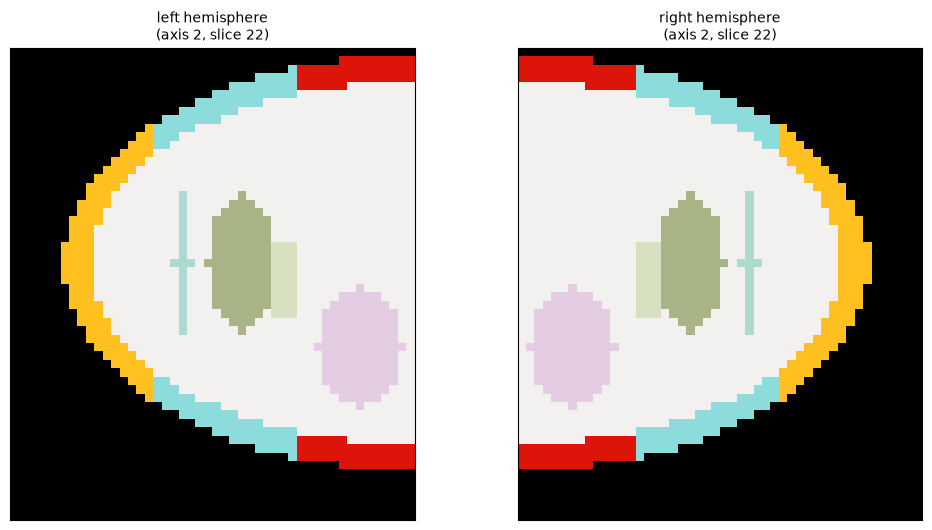

In [2]:
from nextbrain_utils import combine_hemis
from nextbrain_utils.io import load_lut
nxb_lut = load_lut()

left, right = H.make_phantom_hemi("L"), H.make_phantom_hemi("R")
nib.save(left,  WORK / "seg.left.nii.gz")
nib.save(right, WORK / "seg.right.nii.gz")
for name, im in [("left", left), ("right", right)]:
    print(f"{name:5s} shape {im.shape}  origin (mm) {im.affine[:3, 3]}")
H.show_seg([left, right], nxb_lut, axis=2, index=22, titles=["left hemisphere", "right hemisphere"], legend=False)

## How the algorithm works

All computations happen in the **left image's voxel space**.

1. `right2left = inv(A_left) @ A_right` maps right voxel indices to left
   voxel indices.
2. Map the 8 corners of each image's box into left-voxel space, round, and take
   min/max: `left_bbox_min/max` and `right_bbox_min/max`.
3. The union box `[bmin, bmax]` gives the combined shape `bmax − bmin + 1`.
4. Each image becomes a block of slices inside the combined array.
5. The combined affine is `A_left @ T(bmin − left_bbox_min)`, i.e. the left
   affine shifted to the new origin.
6. Copy `left` in, then add `right` **only where the output is still 0**.

Consequence: the method only **translates**, in whole voxels. It assumes both
inputs have the same voxel size and orientation (only the translation in
`right2left` is really honoured, after rounding), and it **never resamples**.
That holds for NextBrain outputs, which share one grid. Do not use it for
arbitrary image pairs.

Let us redo the computation by hand:

In [3]:
from itertools import product
r2l = np.linalg.inv(left.affine) @ right.affine
print("right->left voxel transform:\n", r2l)
corners = np.array(list(product([0, 1], repeat=3)))
lmin, lmax = (corners * (np.array(left.shape) - 1)).min(0), (corners * (np.array(left.shape) - 1)).max(0)
rc = (corners * (np.array(right.shape) - 1)) @ r2l[:3, :3].T + r2l[:3, 3]
rmin, rmax = np.round(rc.min(0)).astype(int), np.round(rc.max(0)).astype(int)
bmin, bmax = np.minimum(lmin, rmin), np.maximum(lmax, rmax)
print("left box ", lmin, lmax, "\nright box", rmin, rmax, "\ncombined shape", bmax - bmin + 1)

right->left voxel transform:
 [[ 1.  0.  0. 46.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
left box  [0 0 0] [47 55 47] 
right box [46  0  0] [93 55 47] 
combined shape [94 56 48]


In [4]:
combined, sides = combine_hemis(WORK / "seg.left.nii.gz", WORK / "seg.right.nii.gz")
print("combined", combined.shape, "dtype", combined.get_data_dtype())
print("affine origin", combined.affine[:3, 3])
print("files written:", sorted(p.name for p in WORK.glob("seg.*.nii.gz")))

combined (94, 56, 48) dtype int16
affine origin [-46.   0.   0.]
files written: ['seg.combined.nii.gz', 'seg.left.nii.gz', 'seg.right.nii.gz', 'seg.sides.nii.gz']


Automatic naming: with `save=True` / `save_sides=True` (the defaults here!),
`.left` in the left file name is replaced by `.combined` and `.sides`. If the
name has no `.left`, the suffix is appended instead. **Note that this function
saves by default**, unlike the converters.

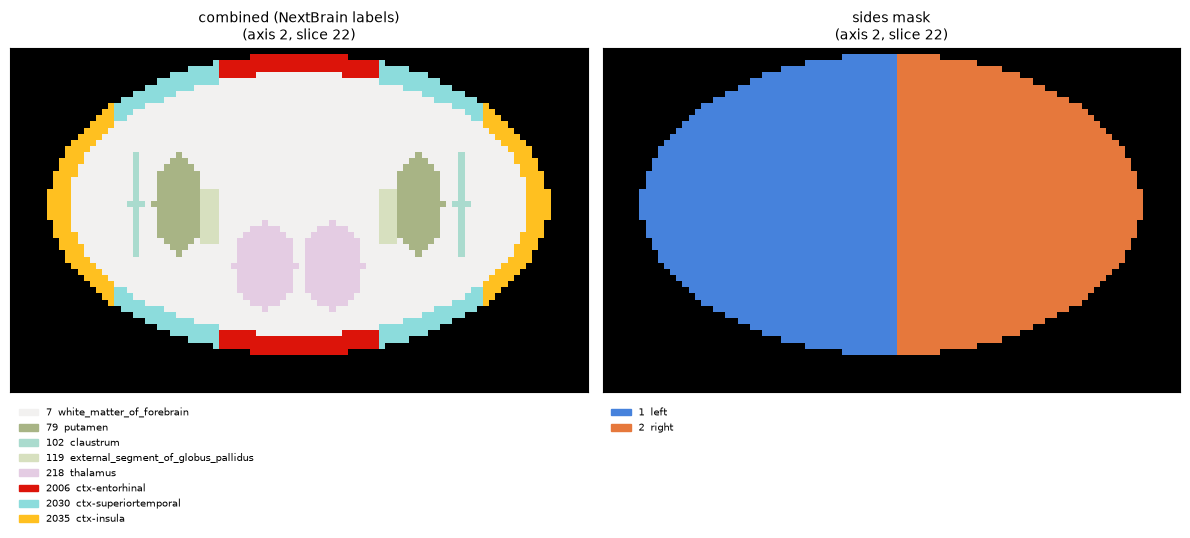

In [5]:
sides_lut = [(1, "left", 70, 130, 220, 0), (2, "right", 230, 120, 60, 0)]
H.show_seg([combined, sides], [nxb_lut, sides_lut], axis=2, index=22,
           titles=["combined (NextBrain labels)", "sides mask"], figsize=(12, 5.5))

### The overlap rule

Our phantoms overlap by 2 voxels at the midline (x = 0, 1 mm). In that band
the left labels are kept, and the right labels only fill voxels that are
background in the left image:

In [6]:
c, s = np.asarray(combined.dataobj), np.asarray(sides.dataobj)
x0 = int(round(np.linalg.inv(combined.affine)[0] @ [0, 0, 0, 1]))   # world x = 0 mm
band = slice(x0, x0 + 2)
print("voxels in the overlap band :", c[band].size)
print("  labelled left (sides==1) :", (s[band] == 1).sum())
print("  labelled right (sides==2):", (s[band] == 2).sum())
print("label counts per side:", {int(k): int(v) for k, v in zip(*np.unique(s, return_counts=True))})

voxels in the overlap band : 5376
  labelled left (sides==1) : 3307
  labelled right (sides==2): 33
label counts per side: {0: 161208, 1: 47369, 2: 44095}


### Small caveats

* The `sides` image reuses `left.header` and calls `set_data_dtype("u1")` on
  it, so the *left image object's* header is modified in place.
* Outputs are written and then **reloaded from disk** (`nb.load(save)`), so the
  returned images are file-backed proxies.
* The CLI (`nextbrain-utils combine`) accepts several `-l/-r` pairs and
  processes them in a loop.

Next: **04 · NextBrain → Allen**.